# Experiment 004 · Learned Utility Scorer 探索性分析

## tl;dr

本 notebook 沿着 **提出假设 → 系统选择 case → 验证/证伪 → 下一步** 的主线，分析实验 004 为什么没有稳定优于 Random/Raw Qwen。

当前证据最强的结论是：

1. **支持：视觉模态内部排序几乎没有学会。** 三个 seed 的 validation Vision–Vision pairwise accuracy 只有约 51.3%–51.7%，而 Text–Text 为 64.5%–67.6%、跨模态为约 69%。
2. **支持：scorer 的总体排序提升很弱，且结构特征可能解释大部分提升。** validation 全局 Spearman 只有 0.086–0.120；仅使用 8 维结构特征和 modality 的 Ridge 弱基线已达到约 53.0% macro pairwise accuracy，接近完整 scorer 的 52.9%–53.3%。这不是“MLP 一定只用了结构特征”的因果证明，但足以说明当前完整模型尚未展示出明显超越简单捷径的排序能力。
3. **部分支持：模态预算和 seed 稳定性会影响下游结果。** 在 50% retention，三个 learned seed 全错的样本，其平均文本预算比例明显低于至少一个 seed 答对的样本；但这是观察性关联，可能受样本难度和证据模态混杂。
4. **证据不足：leave-one-out 交互错位、chunk 内 token 选择错误、NLL 与生成 Accuracy 错位。** 当前产物没有 test oracle utility，也没有保存 token 对应的可读文本/图像区域，因此不能仅靠已有结果把失败归因到这些环节。
5. **发现一个评价实现风险，但它不是本次下游失败的主因。** 项目 pairwise metric 将预测并列按固定方向判断；常数预测器在 Text–Text 上也能得到约 59.3%。完整 scorer 几乎没有精确并列，因此其 53% 不主要由此造成，但后续报告应改用 tie-aware 指标。

> 数据纪律：validation 用于 scorer 诊断与后续方案选择；test 已经被查看，本 notebook 只解释既有实验，不把它继续当作无偏调参集。

## 0. Context & Methods

### 分析边界与文件变更

- 本次只创建并执行 `notebooks/004_exploratory_analysis.ipynb`，**没有新建或修改其他项目代码文件**。
- 用户为本次分析在项目环境中安装了 Jupyter、Matplotlib、Seaborn、SciPy 与 scikit-learn；本 notebook 不修改环境。
- 输入均为已有只读产物：split manifests、utility `.pt` 标签、3 个 scorer checkpoint、训练历史和 test `results.jsonl`。
- test 上没有构造新的 gold utility 标签，也没有重新运行模型生成。

### 核心问题

我们不从“挑一个看起来合理的失败案例”开始，而是先定义可证伪假设和应观察到的证据，再用总体统计选择代表性 case。

In [1]:
from __future__ import annotations

import json
import math
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import torch

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src/mllm_prune").is_dir():
    PROJECT_ROOT = Path("/data2/wenhaozhang/projects/mllm_prune")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from mllm_prune.models.utility_scorer import load_scorer_artifact

RUN_ROOT = Path(os.environ.get(
    "EXPERIMENT_004_RUN_ROOT",
    "/data2/wenhaozhang/runs/mllm_prune/experiment_004",
))
SPLIT_ROOT = PROJECT_ROOT / "data/interim/experiment_004/splits"
RESULTS_PATH = RUN_ROOT / "results.jsonl"

COLORS = {
    "baseline": "#30343b",
    "fixed_joint": "#8c8c8c",
    "random_joint": "#d99a2b",
    "raw_qwen_joint": "#3478b8",
    "learned_utility_joint": "#c65353",
    "text": "#3478b8",
    "vision": "#d99a2b",
}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

required = [
    RESULTS_PATH,
    SPLIT_ROOT / "validation.json",
    SPLIT_ROOT / "test.json",
    *(RUN_ROOT / "checkpoints" / f"seed_{seed}.pt" for seed in range(3)),
]
missing = [str(path) for path in required if not path.exists()]
assert not missing, f"Missing required artifacts: {missing}"

print(f"project: {PROJECT_ROOT}")
print(f"run:     {RUN_ROOT}")
print(f"torch:   {torch.__version__}; CUDA needed for this notebook: no")

project: /data2/wenhaozhang/projects/mllm_prune
run:     /data2/wenhaozhang/runs/mllm_prune/experiment_004
torch:   2.6.0+cu124; CUDA needed for this notebook: no


## 1. 提出失败原因假设

| ID | 可证伪假设 | 如果为真，应观察到什么 | 可用证据 |
| --- | --- | --- | --- |
| H1 | scorer 只学会粗粒度图文区分，没有学会视觉内部排序 | Vision–Vision 指标接近随机，跨模态明显更高 | validation labels + checkpoints |
| H2 | scorer 主要依赖长度、位置、冗余度、模态等结构捷径 | 结构弱基线接近完整 scorer；预测与结构变量强相关 | train/validation cached features |
| H3 | learned 的模态预算分配系统性错误 | 失败样本出现极端预算或与成功样本显著不同 | test plans |
| H4 | scorer seed 不稳定导致选择结果不稳定 | seed 间预测相关低、预算跨度大、同样本答案分歧 | validation predictions + test plans |
| H5 | leave-one-out 标签不适合同时删除大量 chunk | retention 越低相对表现越差；冗余证据被一起删除 | 下游曲线仅能间接支持，需 conditional oracle 才能确认 |
| H6 | scorer 排对了 chunk，但 planner/内部 token selector 删错 | 关键 chunk 高分却未选，或 chunk 被选但证据 token 未保留 | 当前 test 产物不足，需保存可读 chunk/token 映射 |
| H7 | gold-answer NLL utility 与自由生成 Accuracy 错位 | utility 排名好但生成仍失败 | 需同一样本同时具备 oracle utility 与生成结果 |
| H8 | pairwise 指标实现对预测并列存在偏差 | 常数预测也可能偏离 50% | validation labels，可直接复现 |

H1–H4、H8 可以用现有产物直接检验；H5–H7 当前只能给出间接证据或判定“证据不足”。

## 2. Data · 加载与完整性检查

In [2]:
def load_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8"))

test_manifest = load_json(SPLIT_ROOT / "test.json")
validation_manifest = load_json(SPLIT_ROOT / "validation.json")
test_samples = {int(row["sample_id"]): row for row in test_manifest["data"]}
validation_samples = {int(row["sample_id"]): row for row in validation_manifest["data"]}

test_rows = [json.loads(line) for line in RESULTS_PATH.open(encoding="utf-8") if line.strip()]
test_df = pd.DataFrame(test_rows)
test_df["text_budget"] = test_df["plan"].map(lambda plan: plan["text_budget"])
test_df["vision_budget"] = test_df["plan"].map(lambda plan: plan["vision_budget"])
test_df["text_budget_fraction"] = (
    test_df["text_budget"] / (test_df["text_budget"] + test_df["vision_budget"])
)

condition_key = ["sample_id", "method", "retention", "seed"]
integrity = pd.Series({
    "result rows": len(test_df),
    "unique result keys": len(test_df[condition_key].drop_duplicates()),
    "test samples": test_df["sample_id"].nunique(),
    "conditions per sample": int(test_df.groupby("sample_id").size().min()),
    "max |budget deviation|": int(test_df["plan"].map(lambda p: abs(p["budget_deviation"])).max()),
    "FlashAttention2 rows": int((test_df["attention_implementation"] == "flash_attention_2").sum()),
}, name="value").to_frame()
display(integrity)

assert len(test_df) == 1250
assert len(test_df[condition_key].drop_duplicates()) == 1250
assert test_df["sample_id"].nunique() == 50
assert test_df.groupby("sample_id").size().eq(25).all()
assert test_df["plan"].map(lambda p: p["budget_deviation"]).eq(0).all()
assert test_df["attention_implementation"].eq("flash_attention_2").all()

,value
result rows,1250
unique result keys,1250
test samples,50
conditions per sample,25
max |budget deviation|,0
FlashAttention2 rows,1250


## 3. 先看总体结果，再选择 case

In [3]:
condition_summary = (
    test_df.groupby(["method", "retention", "seed"], as_index=False)
    .agg(
        accuracy=("correct", "mean"),
        robust_accuracy=("correct_robust", "mean"),
        text_budget_fraction=("text_budget_fraction", "mean"),
        mean_input_tokens=("compressed_input_tokens", "mean"),
    )
)

method_summary = (
    condition_summary.groupby(["method", "retention"], as_index=False)
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", lambda x: x.std(ddof=0)),
        robust_mean=("robust_accuracy", "mean"),
        seeds=("seed", "nunique"),
    )
)
display(method_summary.style.format({
    "retention": "{:.0%}", "accuracy_mean": "{:.1%}",
    "accuracy_std": "{:.1%}", "robust_mean": "{:.1%}",
}))

,method,retention,accuracy_mean,accuracy_std,robust_mean,seeds
0,baseline,100%,70.0%,0.0%,70.0%,1
1,fixed_joint,25%,42.0%,0.0%,42.0%,1
2,fixed_joint,50%,62.0%,0.0%,62.0%,1
3,fixed_joint,75%,64.0%,0.0%,66.0%,1
4,learned_utility_joint,25%,47.3%,2.5%,49.3%,3
5,learned_utility_joint,50%,60.0%,1.6%,61.3%,3
6,learned_utility_joint,75%,64.7%,2.5%,66.7%,3
7,random_joint,25%,47.3%,0.9%,48.7%,3
8,random_joint,50%,62.7%,4.1%,64.0%,3
9,random_joint,75%,64.0%,3.3%,66.0%,3


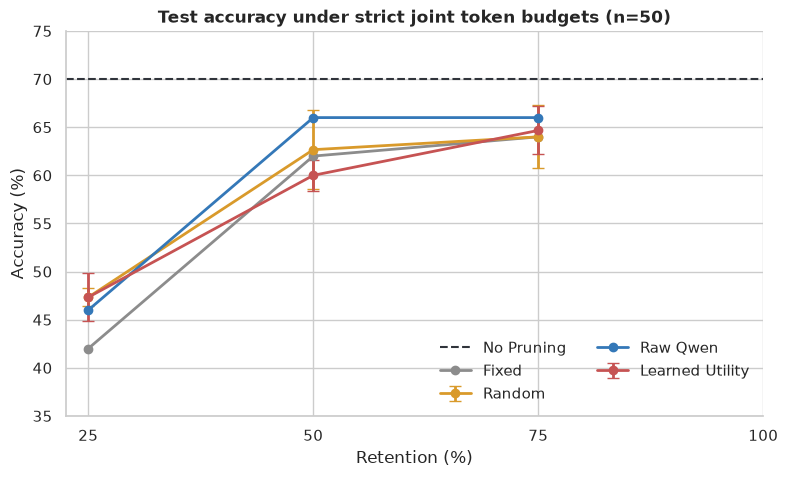

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
for method in ["fixed_joint", "random_joint", "raw_qwen_joint", "learned_utility_joint"]:
    part = method_summary[method_summary["method"] == method].sort_values("retention")
    ax.errorbar(
        part["retention"] * 100,
        part["accuracy_mean"] * 100,
        yerr=part["accuracy_std"] * 100 if method in {"random_joint", "learned_utility_joint"} else None,
        marker="o", linewidth=2, capsize=4,
        label=method.replace("_joint", "").replace("_", " ").title(),
        color=COLORS[method],
    )
baseline_accuracy = float(method_summary.loc[method_summary["method"] == "baseline", "accuracy_mean"].iloc[0])
ax.axhline(baseline_accuracy * 100, color=COLORS["baseline"], linestyle="--", label="No Pruning")
ax.set(title="Test accuracy under strict joint token budgets (n=50)", xlabel="Retention (%)", ylabel="Accuracy (%)", xticks=[25, 50, 75, 100], ylim=(35, 75))
ax.legend(frameon=False, ncol=2)
plt.show()

观察：Learned 在 75% 仅略高于 Random 均值，在 50% 低于 Random 与 Raw Qwen，在 25% 与 Random 均值相同。下一步不随机挑 case，而是在预先定义的 outcome pattern 中选择。

## 4. 选择 case · 先分类再抽取代表样本

,samples
A · Baseline+Raw 对，3 个 Learned 全错,2
B · Baseline 对，所有已测 pruning 全错,2
C · Learned seed 间有分歧,7
D · Baseline 错，至少一个 Learned 对,3
E · Baseline 对，3 个 Learned 全对,25


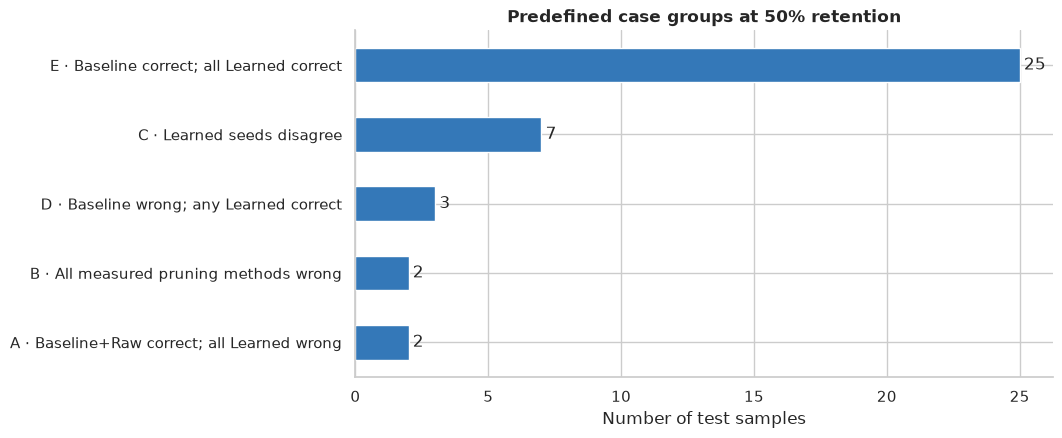

In [5]:
PRIMARY_RETENTION = 0.50

def correctness_series(method: str, seed: int = 0, retention: float = PRIMARY_RETENTION):
    effective_retention = 1.0 if method == "baseline" else retention
    part = test_df[
        (test_df["method"] == method)
        & (test_df["seed"] == seed)
        & (test_df["retention"] == effective_retention)
    ]
    return part.set_index("sample_id")["correct"].astype(bool)

baseline_correct = correctness_series("baseline")
raw_correct = correctness_series("raw_qwen_joint")
learned_correct = pd.concat(
    [correctness_series("learned_utility_joint", seed).rename(seed) for seed in range(3)], axis=1
)
random_correct = pd.concat(
    [correctness_series("random_joint", seed).rename(seed) for seed in range(3)], axis=1
)

case_masks = {
    "A · Baseline+Raw 对，3 个 Learned 全错": baseline_correct & raw_correct & ~learned_correct.any(axis=1),
    "B · Baseline 对，所有已测 pruning 全错": baseline_correct & ~raw_correct & ~learned_correct.any(axis=1) & ~random_correct.any(axis=1),
    "C · Learned seed 间有分歧": learned_correct.nunique(axis=1) > 1,
    "D · Baseline 错，至少一个 Learned 对": ~baseline_correct & learned_correct.any(axis=1),
    "E · Baseline 对，3 个 Learned 全对": baseline_correct & learned_correct.all(axis=1),
}
case_counts = pd.Series({name: int(mask.sum()) for name, mask in case_masks.items()}, name="samples")
display(case_counts.to_frame())

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_case_counts = case_counts.copy()
plot_case_counts.index = [
    "A · Baseline+Raw correct; all Learned wrong",
    "B · All measured pruning methods wrong",
    "C · Learned seeds disagree",
    "D · Baseline wrong; any Learned correct",
    "E · Baseline correct; all Learned correct",
]
plot_case_counts.sort_values().plot.barh(ax=ax, color="#3478b8")
ax.set(title="Predefined case groups at 50% retention", xlabel="Number of test samples", ylabel="")
ax.bar_label(ax.containers[0], padding=3)
plt.show()

In [6]:
def current_question(sample: dict) -> str:
    context = str(sample["task_instance"]["context"])
    marker = context.rfind("Question:")
    return context[marker + len("Question:"):].replace("Answer:", "").strip()

def condition_row(sample_id: int, method: str, seed: int = 0, retention: float = PRIMARY_RETENTION):
    effective_retention = 1.0 if method == "baseline" else retention
    return test_df[
        (test_df["sample_id"] == sample_id)
        & (test_df["method"] == method)
        & (test_df["seed"] == seed)
        & (test_df["retention"] == effective_retention)
    ].iloc[0]

priority_ids = list(case_masks["A · Baseline+Raw 对，3 个 Learned 全错"].loc[lambda x: x].index)
selected_case_rows = []
for sample_id in priority_ids:
    sample = test_samples[int(sample_id)]
    baseline = condition_row(sample_id, "baseline")
    raw = condition_row(sample_id, "raw_qwen_joint")
    learned = [condition_row(sample_id, "learned_utility_joint", seed) for seed in range(3)]
    selected_case_rows.append({
        "sample_id": sample_id,
        "question": current_question(sample),
        "gold": sample["response"],
        "baseline": baseline["prediction"],
        "raw": raw["prediction"],
        "learned predictions (s0 | s1 | s2)": " | ".join(row["prediction"] for row in learned),
        "learned text budgets": "/".join(str(int(row["text_budget"])) for row in learned),
    })
selected_cases = pd.DataFrame(selected_case_rows)
display(selected_cases.style.set_properties(subset=["question"], **{"max-width": "420px", "white-space": "normal"}))

,sample_id,question,gold,baseline,raw,learned predictions (s0 | s1 | s2),learned text budgets
0,18,Which college is affiliated to the former MLS team Los Angeles Galaxy?,San Diego State,San Diego State.,San Diego State.,"West Texas A&M. | The Los Angeles Galaxy is affiliated with the University of California, Los Angeles (UCLA). | The information provided does not contain any data related to the college affiliation of the Los Angeles Galaxy. The table only lists the players and their teams for the 2",561/561/457
1,72,How many leaves are on the clover on this team's logo?,four,The clover on the Celtic F.C. logo has four leaves.,The clover on the Celtic F.C. logo has four leaves.,4 | 4 | 3,242/242/226


选择规则固定为：优先分析 **50% retention、Baseline 与 Raw 都正确、三个 Learned 全错** 的样本。这样尽量排除“基础模型不会”和“该预算必然不够”，把注意力集中到 learned 组件引入的退化。当前严格满足条件的是 sample 18、107；若放宽为“至少一个 Learned seed 错”，还会包含 sample 51、72、114。

这些 case 仍然只是诊断入口；不能因为它们支持某个故事就直接确认根因。

## 5. 验证 scorer 假设 · 重建 validation 预测

In [7]:
def load_label_records(split: str):
    directory = RUN_ROOT / "labels" / split
    paths = sorted(directory.glob("*.pt"), key=lambda path: int(path.stem))
    return [torch.load(path, map_location="cpu", weights_only=True) for path in paths]

validation_records = load_label_records("validation")
assert len(validation_records) == 30

scorers = {}
for seed in range(3):
    scorers[seed] = load_scorer_artifact(
        RUN_ROOT / "checkpoints" / f"seed_{seed}.pt", torch.device("cpu")
    )

chunk_rows = []
with torch.inference_mode():
    for record in validation_records:
        features = record["features"]
        labels = record["utility_labels"].float()
        modalities = features["modality_ids"].long()
        structural = features["structural_features"].float()
        capacities = list(features["chunk_capacities"])
        for seed, (model, artifact) in scorers.items():
            normalized = model(
                features["chunk_features"].float(),
                features["question_feature"].float(),
                modalities,
                structural,
            )
            predictions = normalized * float(artifact["label_scale"]) + float(artifact["label_center"])
            for chunk_index in range(len(labels)):
                row = {
                    "sample_id": int(record["sample_id"]),
                    "seed": seed,
                    "chunk_index": chunk_index,
                    "modality_id": int(modalities[chunk_index]),
                    "modality": "Text" if int(modalities[chunk_index]) == 0 else "Vision",
                    "capacity": int(capacities[chunk_index]),
                    "label": float(labels[chunk_index]),
                    "prediction": float(predictions[chunk_index]),
                }
                names = [
                    "log_capacity", "relative_capacity", "order", "source_id",
                    "modality_chunk_share", "modality_token_share",
                    "max_redundancy", "mean_redundancy",
                ]
                row.update({name: float(structural[chunk_index, i]) for i, name in enumerate(names)})
                chunk_rows.append(row)

validation_chunks = pd.DataFrame(chunk_rows)
print(f"validation predictions: {len(validation_chunks):,} rows = 5,023 chunks × 3 seeds")
display(validation_chunks.head())

validation predictions: 15,069 rows = 5,023 chunks × 3 seeds


,sample_id,seed,chunk_index,modality_id,modality,capacity,label,prediction,log_capacity,relative_capacity,order,source_id,modality_chunk_share,modality_token_share,max_redundancy,mean_redundancy
0,1,0,0,0,Text,4,-0.050686,-0.068523,1.609438,0.044944,0.00,0.00,0.03268,0.041961,0.636114,0.584376
1,1,0,1,0,Text,6,-0.231399,-0.074483,1.945910,0.067416,0.25,0.25,0.03268,0.041961,0.714780,0.652446
2,1,0,2,0,Text,30,0.112485,0.021159,3.433987,0.337079,0.50,0.50,0.03268,0.041961,0.972992,0.783270
3,1,0,3,0,Text,23,0.284181,0.027720,3.178054,0.258427,0.75,0.75,0.03268,0.041961,0.811883,0.719055
4,1,0,4,0,Text,26,-0.096113,0.024255,3.295837,0.292135,1.00,1.00,0.03268,0.041961,0.972992,0.729625


### 5.1 H1 · 模态内部和跨模态排序

In [8]:
def pair_mask(modalities: np.ndarray, left: np.ndarray, right: np.ndarray, pair_type: str):
    if pair_type == "Text–Text":
        return (modalities[left] == 0) & (modalities[right] == 0)
    if pair_type == "Vision–Vision":
        return (modalities[left] == 1) & (modalities[right] == 1)
    if pair_type == "Text–Vision":
        return modalities[left] != modalities[right]
    return np.ones(len(left), dtype=bool)

def pairwise_accuracy_values(group: pd.DataFrame, pair_type: str, tie_score: float = 0.5):
    labels = group["label"].to_numpy()
    predictions = group["prediction"].to_numpy()
    modalities = group["modality_id"].to_numpy()
    left, right = np.triu_indices(len(group), 1)
    label_gap = labels[left] - labels[right]
    keep = (np.abs(label_gap) > 0.001) & pair_mask(modalities, left, right, pair_type)
    pred_gap = predictions[left] - predictions[right]
    if not keep.any():
        return np.nan
    score = ((pred_gap > 0) == (label_gap > 0)).astype(float)
    score[np.isclose(pred_gap, 0.0, atol=1e-12)] = tie_score
    return float(score[keep].mean())

pair_types = ["All", "Text–Text", "Vision–Vision", "Text–Vision"]
metric_rows = []
for seed in range(3):
    seed_data = validation_chunks[validation_chunks["seed"] == seed]
    for pair_type in pair_types:
        sample_scores = [
            pairwise_accuracy_values(group, pair_type)
            for _, group in seed_data.groupby("sample_id")
        ]
        metric_rows.append({
            "seed": seed,
            "pair_type": pair_type,
            "macro_pairwise_accuracy": float(np.nanmean(sample_scores)),
        })
pair_metrics = pd.DataFrame(metric_rows)
display(pair_metrics.pivot(index="pair_type", columns="seed", values="macro_pairwise_accuracy").style.format("{:.1%}"))

seed,0,1,2
pair_type,,,
All,52.9%,53.1%,53.3%
Text–Text,65.2%,64.5%,67.6%
Text–Vision,69.0%,69.0%,69.0%
Vision–Vision,51.3%,51.5%,51.7%


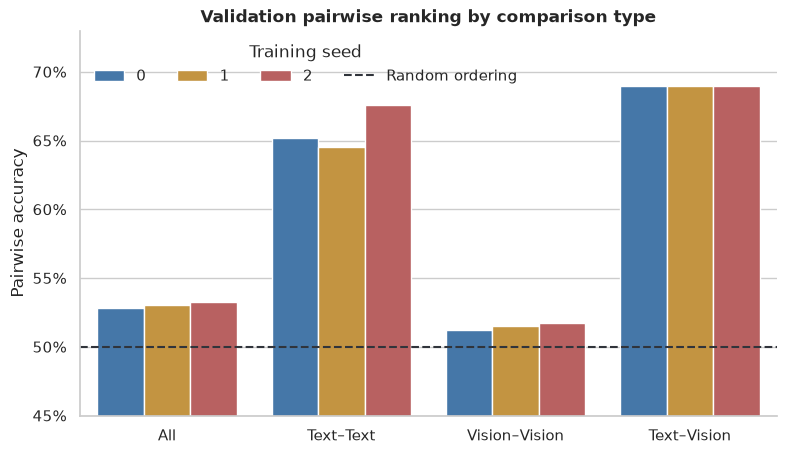

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=pair_metrics, x="pair_type", y="macro_pairwise_accuracy", hue="seed",
    palette=["#3478b8", "#d99a2b", "#c65353"], ax=ax,
)
ax.axhline(0.5, color="#30343b", linestyle="--", linewidth=1.5, label="Random ordering")
ax.set(title="Validation pairwise ranking by comparison type", xlabel="", ylabel="Pairwise accuracy", ylim=(0.45, 0.73))
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax.legend(title="Training seed", frameon=False, ncol=4)
plt.show()

**H1 得到强支持。** Vision–Vision 只有约 51.3%–51.7%，基本等于随机；Text–Text 和 Text–Vision 明显更高。由于视觉 chunk 占 validation 的约 94.9%，实际 pruning 中大量决策正是 scorer 最不擅长的视觉内部排序。

### 5.2 全局相关性、Top-k recall 与输出尺度

In [10]:
quality_rows = []
for seed in range(3):
    part = validation_chunks[validation_chunks["seed"] == seed]
    for modality in ["All", "Text", "Vision"]:
        selected = part if modality == "All" else part[part["modality"] == modality]
        rho = spearmanr(selected["label"], selected["prediction"]).statistic
        quality_rows.append({"seed": seed, "scope": modality, "spearman": rho})

topk_rows = []
for seed in range(3):
    part = validation_chunks[validation_chunks["seed"] == seed]
    for fraction in [0.10, 0.25, 0.50]:
        recalls = []
        for _, group in part.groupby("sample_id"):
            k = max(1, round(len(group) * fraction))
            true_top = set(group.nlargest(k, "label")["chunk_index"])
            pred_top = set(group.nlargest(k, "prediction")["chunk_index"])
            recalls.append(len(true_top & pred_top) / k)
        topk_rows.append({"seed": seed, "top_fraction": fraction, "recall": np.mean(recalls)})

quality_table = pd.DataFrame(quality_rows).pivot(index="scope", columns="seed", values="spearman")
topk_table = pd.DataFrame(topk_rows).pivot(index="top_fraction", columns="seed", values="recall")
display(Markdown("**Spearman rank correlation**"), quality_table.style.format("{:.3f}"))
display(Markdown("**Top-k utility recall**"), topk_table.style.format("{:.1%}"))

**Spearman rank correlation**

seed,0,1,2
scope,,,
All,0.120,0.086,0.103
Text,0.319,0.346,0.366
Vision,0.095,0.057,0.074


**Top-k utility recall**

seed,0,1,2
top_fraction,,,
0.100000,26.3%,25.9%,20.5%
0.250000,29.7%,30.6%,28.3%
0.500000,52.1%,51.6%,51.9%


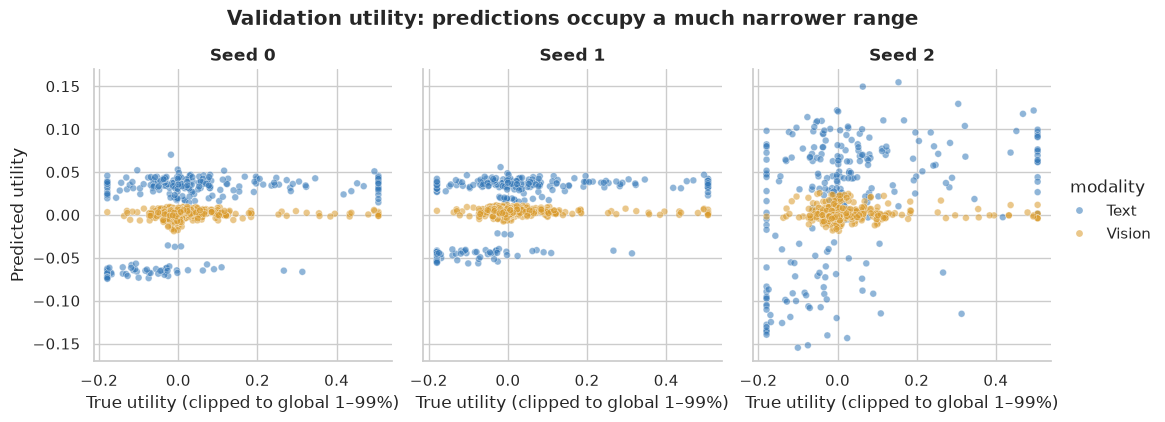

In [11]:
plot_data = validation_chunks.copy()
plot_data["label_clipped"] = plot_data["label"].clip(
    plot_data["label"].quantile(0.01), plot_data["label"].quantile(0.99)
)
sampled = pd.concat(
    [group.sample(n=min(700, len(group)), random_state=2026)
     for _, group in plot_data.groupby(["seed", "modality"])],
    ignore_index=True,
)
g = sns.relplot(
    data=sampled, x="label_clipped", y="prediction", col="seed", hue="modality",
    palette={"Text": COLORS["text"], "Vision": COLORS["vision"]},
    alpha=0.55, s=24, height=4, aspect=0.9,
)
g.set_axis_labels("True utility (clipped to global 1–99%)", "Predicted utility")
g.set_titles("Seed {col_name}")
g.figure.suptitle("Validation utility: predictions occupy a much narrower range", y=1.05, fontweight="bold")
plt.show()

总体 Spearman 仅 0.086–0.120，视觉内部仅 0.057–0.095。Top-10% recall 为 20.5%–26.3%，高于随机期望 10%，但仍漏掉约四分之三真实高 utility chunk。散点还显示预测范围明显收缩，尤其视觉预测大量挤在零附近。

### 5.3 H2 · 简单结构弱基线能解释多少？

In [12]:
train_records = load_label_records("train")
structural_names = [
    "log_capacity", "relative_capacity", "order", "source_id",
    "modality_chunk_share", "modality_token_share",
    "max_redundancy", "mean_redundancy",
]

def structural_matrix(records):
    matrices, labels = [], []
    for record in records:
        structural = record["features"]["structural_features"].float().numpy()
        modality = record["features"]["modality_ids"].float().numpy()[:, None]
        matrices.append(np.concatenate([structural, modality], axis=1))
        labels.append(record["utility_labels"].float().numpy())
    return np.concatenate(matrices), np.concatenate(labels)

train_x, train_y = structural_matrix(train_records)
structural_model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
structural_model.fit(train_x, train_y)

weak_rows = []
for record in validation_records:
    structural = record["features"]["structural_features"].float().numpy()
    modality = record["features"]["modality_ids"].float().numpy()
    features = np.concatenate([structural, modality[:, None]], axis=1)
    predictions = structural_model.predict(features)
    labels = record["utility_labels"].float().numpy()
    frame = pd.DataFrame({"label": labels, "prediction": predictions, "modality_id": modality})
    for pair_type in pair_types:
        weak_rows.append({
            "sample_id": int(record["sample_id"]),
            "pair_type": pair_type,
            "accuracy": pairwise_accuracy_values(frame, pair_type),
        })
weak_metrics = pd.DataFrame(weak_rows).groupby("pair_type")["accuracy"].mean()
full_best = pair_metrics.groupby("pair_type")["macro_pairwise_accuracy"].max()
comparison = pd.DataFrame({
    "Structure+modality Ridge": weak_metrics,
    "Best full scorer seed": full_best,
})
display(comparison.style.format("{:.1%}"))

,Structure+modality Ridge,Best full scorer seed
pair_type,,
All,53.0%,53.3%
Text–Text,58.6%,67.6%
Text–Vision,63.7%,69.0%
Vision–Vision,51.8%,51.7%


In [13]:
correlation_rows = []
for seed in range(3):
    part = validation_chunks[validation_chunks["seed"] == seed]
    for feature in structural_names:
        correlation_rows.append({
            "seed": seed,
            "feature": feature,
            "spearman": spearmanr(part[feature], part["prediction"]).statistic,
        })
correlation_table = pd.DataFrame(correlation_rows).pivot(index="feature", columns="seed", values="spearman")
display(correlation_table.style.format("{:.3f}").background_gradient(cmap="coolwarm", vmin=-0.5, vmax=0.5))

seed,0,1,2
feature,,,
log_capacity,0.428,0.497,0.301
max_redundancy,0.104,0.088,-0.183
mean_redundancy,0.238,0.194,0.026
modality_chunk_share,0.010,-0.019,-0.078
modality_token_share,0.007,-0.015,-0.012
order,-0.063,-0.070,0.069
relative_capacity,0.346,0.388,0.221
source_id,-0.029,-0.016,0.093


**H2 得到支持，但不是完全证明。** 结构+模态 Ridge 的总体 macro pairwise accuracy 已约 53.0%，几乎覆盖完整 scorer 的 52.9%–53.3%；其 Vision–Vision 同样只有约 51.8%。完整 scorer 的预测还与 chunk 长度相关结构量呈中等相关。要严格证明 MLP 是否忽略语义特征，下一轮应训练 modality-only、structure-only、Qwen-feature-only 三个同构 scorer；当前 Ridge 只能说明“简单结构信息足以复现总体弱指标”。

### 5.4 H8 · Pairwise metric 的预测并列问题

In [14]:
def project_metric_with_constant_prediction(record, pair_type):
    labels = record["utility_labels"].float().numpy()
    modalities = record["features"]["modality_ids"].numpy()
    left, right = np.triu_indices(len(labels), 1)
    gap = labels[left] - labels[right]
    keep = (np.abs(gap) > 0.001) & pair_mask(modalities, left, right, pair_type)
    # 与项目当前实现一致：predicted_gap == 0 会被当成“非正方向”。
    return float(((np.zeros_like(gap) > 0) == (gap > 0))[keep].mean()) if keep.any() else np.nan

constant_scores = {
    pair_type: np.nanmean([
        project_metric_with_constant_prediction(record, pair_type)
        for record in validation_records
    ])
    for pair_type in pair_types
}

exact_tie_rates = {}
for seed in range(3):
    tied = total = 0
    for _, group in validation_chunks[validation_chunks["seed"] == seed].groupby("sample_id"):
        predictions = group["prediction"].to_numpy()
        left, right = np.triu_indices(len(group), 1)
        tied += int(np.isclose(predictions[left] - predictions[right], 0.0, atol=1e-12).sum())
        total += len(left)
    exact_tie_rates[seed] = tied / total

display(pd.DataFrame({
    "current metric · constant predictor": pd.Series(constant_scores),
    "tie-aware expected score": 0.5,
}).style.format("{:.1%}"))
display(pd.Series(exact_tie_rates, name="full scorer exact prediction-pair tie rate").to_frame().style.format("{:.3%}"))

,current metric · constant predictor,tie-aware expected score
All,50.2%,50.0%
Text–Text,59.3%,50.0%
Vision–Vision,50.2%,50.0%
Text–Vision,52.6%,50.0%


,full scorer exact prediction-pair tie rate
0,0.000%
1,0.000%
2,0.000%


**H8 被确认：当前 metric 对并列预测有方向偏差。** 常数预测器在 Text–Text 上也得到约 59.3%，因为文本真实 utility 与 chunk 顺序存在关联，而并列被统一当成“后一个更高”。

但完整 scorer 的精确预测并列率接近零，所以这个实现问题不会直接把 scorer 的 53% 大幅抬高，也不能解释下游 Accuracy 失败。它仍应在后续修正为：并列计 0.5、排除并列并单独报告覆盖率，或使用 Kendall tau-b。

### 5.5 H4 · 三个 scorer seed 是否稳定？

seed,0,1,2
seed,,,
0,1.000,0.913,0.415
1,0.913,1.000,0.473
2,0.415,0.473,1.000


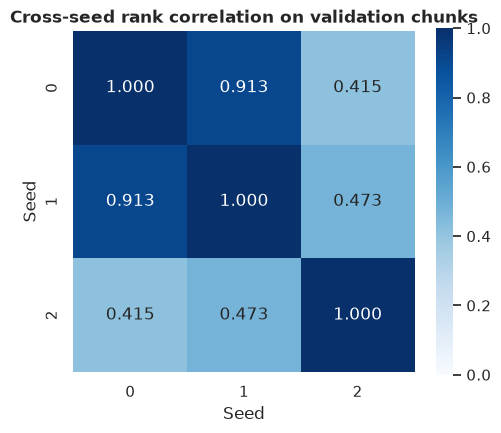

In [15]:
prediction_wide = validation_chunks.pivot(
    index=["sample_id", "chunk_index"], columns="seed", values="prediction"
)
seed_correlation = prediction_wide.corr(method="spearman")
display(seed_correlation.style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0, vmax=1))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(seed_correlation, annot=True, fmt=".3f", vmin=0, vmax=1, cmap="Blues", square=True, ax=ax)
ax.set(title="Cross-seed rank correlation on validation chunks", xlabel="Seed", ylabel="Seed")
plt.show()

In [16]:
learned_test = test_df[
    (test_df["method"] == "learned_utility_joint")
    & (test_df["retention"].isin([0.25, 0.50, 0.75]))
]
budget_ranges = (
    learned_test.groupby(["retention", "sample_id"])["text_budget"]
    .agg(lambda values: values.max() - values.min())
    .rename("text_budget_range")
    .reset_index()
)
budget_range_summary = budget_ranges.groupby("retention")["text_budget_range"].agg(["mean", "median", "max"])
display(budget_range_summary.style.format("{:.1f}"))

,mean,median,max
retention,,,
0.250000,46.9,14.5,273.0
0.500000,29.7,0.0,210.0
0.750000,16.0,0.0,217.0


**H4 部分成立。** seed 0/1 的预测排序高度一致（Spearman 约 0.91），但 seed 2 与前两者只有约 0.41–0.47。个别 test 样本的文本预算跨 seed 相差 200 个以上 token。另一方面，下游 Accuracy 的 seed 标准差只有约 1.6%–2.5%，所以 seed 不稳定是风险，但不是 50% 下三个 seed 都弱于 Raw Qwen 的唯一解释。

## 6. Test 预算与失败关联（观察性，不作因果结论）

In [17]:
budget_diagnostic_rows = []
for retention in [0.75, 0.50, 0.25]:
    part = learned_test[learned_test["retention"] == retention]
    sample_level = part.groupby("sample_id").agg(
        learned_accuracy=("correct", "mean"),
        text_fraction=("text_budget_fraction", "mean"),
        text_fraction_sd=("text_budget_fraction", "std"),
        text_budget_range=("text_budget", lambda x: x.max() - x.min()),
    )
    sample_level["outcome"] = np.where(
        sample_level["learned_accuracy"].eq(0), "All 3 seeds wrong", "At least 1 seed correct"
    )
    for outcome, group in sample_level.groupby("outcome"):
        budget_diagnostic_rows.append({
            "retention": retention,
            "outcome": outcome,
            "samples": len(group),
            "mean_text_fraction": group["text_fraction"].mean(),
            "mean_seed_budget_range": group["text_budget_range"].mean(),
        })
budget_diagnostics = pd.DataFrame(budget_diagnostic_rows)
display(budget_diagnostics.style.format({"retention": "{:.0%}", "mean_text_fraction": "{:.1%}", "mean_seed_budget_range": "{:.1f}"}))

,retention,outcome,samples,mean_text_fraction,mean_seed_budget_range
0,75%,All 3 seeds wrong,16,21.2%,1.8
1,75%,At least 1 seed correct,34,31.1%,22.7
2,50%,All 3 seeds wrong,17,28.8%,17.6
3,50%,At least 1 seed correct,33,45.2%,35.9
4,25%,All 3 seeds wrong,23,56.7%,31.3
5,25%,At least 1 seed correct,27,62.3%,60.1


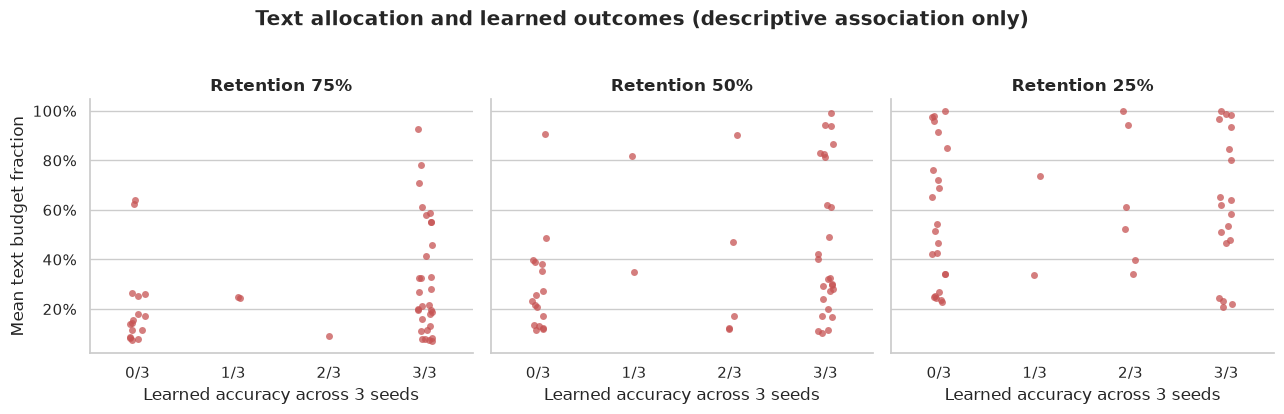

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, retention in zip(axes, [0.75, 0.50, 0.25]):
    part = learned_test[learned_test["retention"] == retention]
    sample_level = part.groupby("sample_id").agg(
        learned_accuracy=("correct", "mean"),
        text_fraction=("text_budget_fraction", "mean"),
    ).reset_index()
    sns.stripplot(
        data=sample_level, x="learned_accuracy", y="text_fraction",
        color=COLORS["learned_utility_joint"], alpha=0.75, jitter=0.08, ax=ax,
    )
    ax.set(title=f"Retention {retention:.0%}", xlabel="Learned accuracy across 3 seeds", ylabel="Mean text budget fraction" if retention == 0.75 else "")
    ax.set_xticks([0, 1, 2, 3], labels=["0/3", "1/3", "2/3", "3/3"])
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
fig.suptitle("Text allocation and learned outcomes (descriptive association only)", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()

在 50% retention，三个 learned seed 全错的 16 个样本平均文本预算比例约 28.8%，至少一个 seed 正确的 33 个样本约 45.2%。这支持继续检查模态预算，但不能直接得出“多给文本就会答对”：需要控制问题证据模态，并在 validation 上做固定预算或 oracle allocation 对照。

## 7. Case 可视化

### 7.1 Test 代表案例：sample 18

这个案例满足预设的严格 A 类规则：50% 下 Baseline 与 Raw Qwen 正确，三个 Learned 全错。现有 test JSONL 保存了 chunk 分数、预算和生成答案，但没有保存可读 chunk 文本、视觉窗口坐标或 oracle utility，因此下面只能定位“选择行为差异”，不能证明具体证据被哪一步删掉。

In [19]:
CASE_ID = 18
sample = test_samples[CASE_ID]
case_conditions = [condition_row(CASE_ID, "baseline"), condition_row(CASE_ID, "raw_qwen_joint")]
case_conditions += [condition_row(CASE_ID, "learned_utility_joint", seed) for seed in range(3)]
case_summary = pd.DataFrame([{
    "method": row["method"],
    "seed": int(row["seed"]),
    "prediction": row["prediction"],
    "correct": bool(row["correct"]),
    "text_budget": int(row["text_budget"]),
    "vision_budget": int(row["vision_budget"]),
} for row in case_conditions])

display(Markdown(f"**Question:** {current_question(sample)}  \n**Gold:** {sample['response']}"))
display(case_summary)

**Question:** Which college is affiliated to the former MLS team Los Angeles Galaxy?  
**Gold:** San Diego State

,method,seed,prediction,correct,text_budget,vision_budget
0,baseline,0,San Diego State.,True,571,2424
1,raw_qwen_joint,0,San Diego State.,True,571,926
2,learned_utility_joint,0,West Texas A&M.,False,561,936
3,learned_utility_joint,1,The Los Angeles Galaxy is affiliated with the ...,False,561,936
4,learned_utility_joint,2,The information provided does not contain any ...,False,457,1040


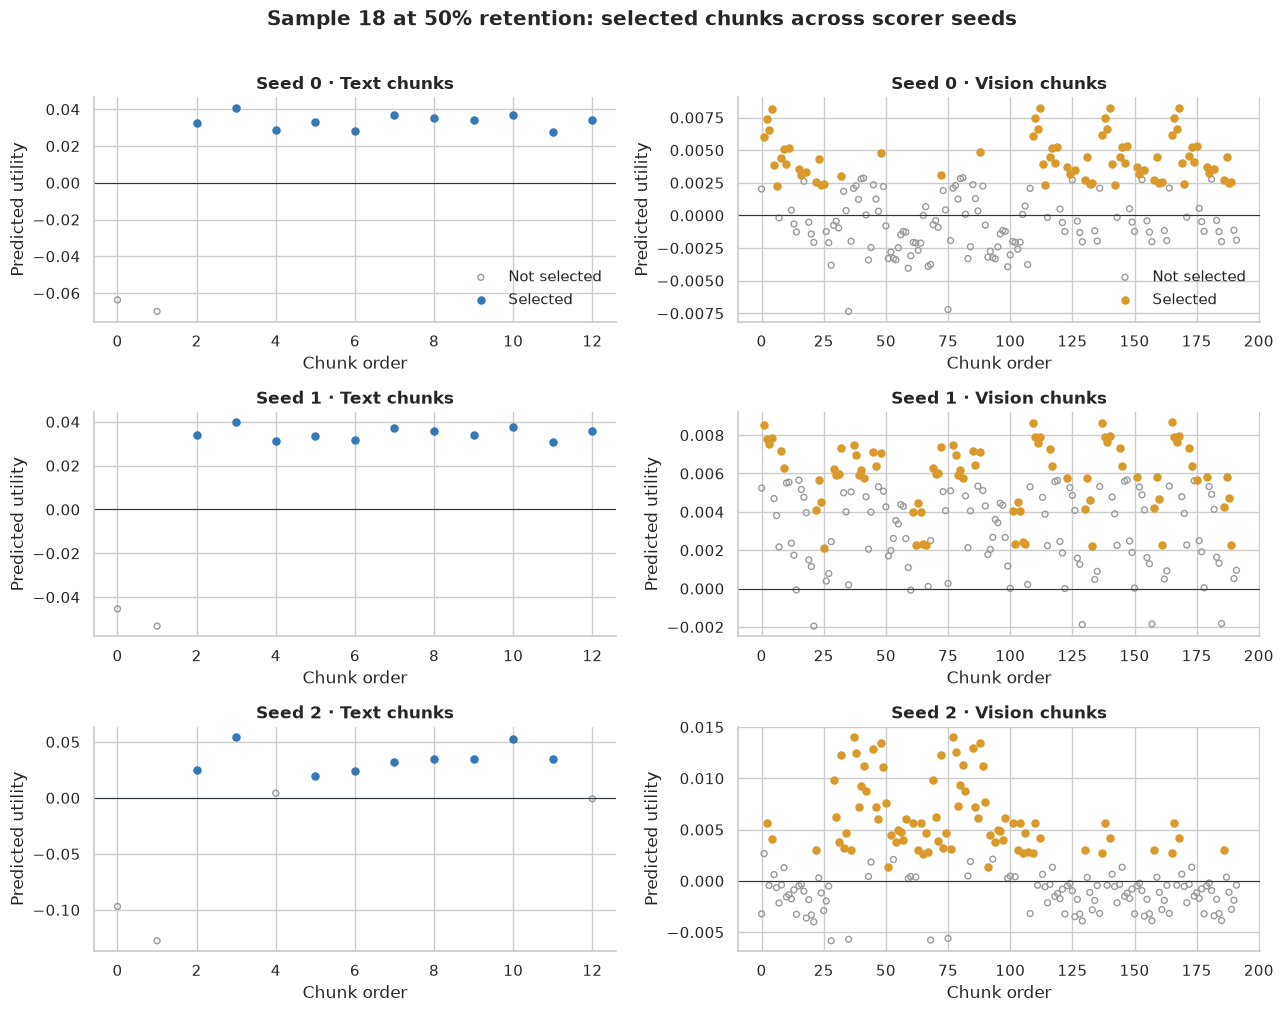

In [20]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for seed, row_axes in zip(range(3), axes):
    row = condition_row(CASE_ID, "learned_utility_joint", seed)
    plan = row["plan"]
    for ax, modality, color in zip(row_axes, ["text", "vision"], [COLORS["text"], COLORS["vision"]]):
        scores = np.asarray(plan[f"{modality}_chunk_scores"], dtype=float)
        budgets = np.asarray(plan[f"{modality}_chunk_budgets"], dtype=float)
        selected = budgets > 0
        ax.scatter(np.arange(len(scores))[~selected], scores[~selected], s=18, facecolors="none", edgecolors="#9a9a9a", label="Not selected")
        ax.scatter(np.arange(len(scores))[selected], scores[selected], s=26, color=color, label="Selected")
        ax.set(title=f"Seed {seed} · {modality.title()} chunks", xlabel="Chunk order", ylabel="Predicted utility")
        ax.axhline(0, color="#30343b", linewidth=0.8)
        if seed == 0:
            ax.legend(frameon=False)
fig.suptitle("Sample 18 at 50% retention: selected chunks across scorer seeds", y=1.01, fontweight="bold")
plt.tight_layout()
plt.show()

这个图能确认不同 seed 的 score 尺度和选择边界不同，但不能仅凭 chunk 顺序判断哪一个包含答案。要完成语义 case analysis，需要下一轮在推理产物中额外保存：文本 chunk 的字符片段、视觉 chunk 的 image/source ID 与窗口坐标、chunk capacity、最终保留 token 映射。

### 7.2 Validation 反例：自动选择视觉排序最差的样本

,vv_accuracy
sample_id,
77,46.3%
117,46.6%
163,47.2%
172,47.5%
142,48.0%


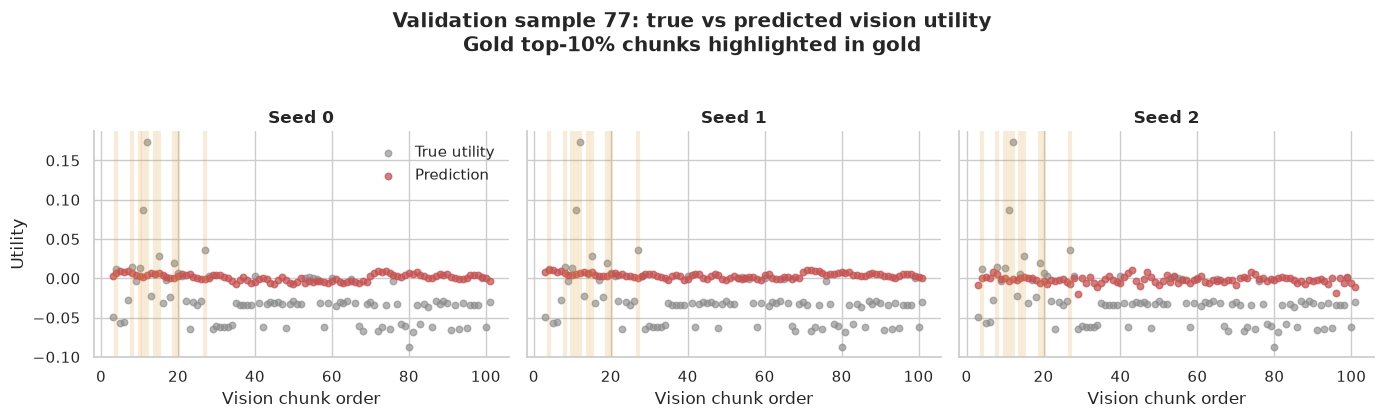

In [21]:
sample_metric_rows = []
for seed in range(3):
    part = validation_chunks[validation_chunks["seed"] == seed]
    for sample_id, group in part.groupby("sample_id"):
        sample_metric_rows.append({
            "sample_id": sample_id,
            "seed": seed,
            "vv_accuracy": pairwise_accuracy_values(group, "Vision–Vision"),
            "all_accuracy": pairwise_accuracy_values(group, "All"),
        })
sample_metrics = pd.DataFrame(sample_metric_rows)
worst_validation = (
    sample_metrics.groupby("sample_id")["vv_accuracy"].mean().sort_values().head(5).to_frame()
)
display(worst_validation.style.format("{:.1%}"))

WORST_ID = int(worst_validation.index[0])
worst = validation_chunks[validation_chunks["sample_id"] == WORST_ID]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for seed, ax in zip(range(3), axes):
    part = worst[(worst["seed"] == seed) & (worst["modality"] == "Vision")].copy()
    top_true = set(part.nlargest(max(1, round(len(part) * 0.10)), "label")["chunk_index"])
    ax.scatter(part["chunk_index"], part["label"], s=22, color="#8c8c8c", alpha=0.65, label="True utility")
    ax.scatter(part["chunk_index"], part["prediction"], s=22, color=COLORS["learned_utility_joint"], alpha=0.75, label="Prediction")
    for chunk_index in top_true:
        point = part[part["chunk_index"] == chunk_index].iloc[0]
        ax.axvline(chunk_index, color=COLORS["vision"], alpha=0.18, linewidth=3)
    ax.set(title=f"Seed {seed}", xlabel="Vision chunk order", ylabel="Utility" if seed == 0 else "")
    if seed == 0:
        ax.legend(frameon=False)
fig.suptitle(f"Validation sample {WORST_ID}: true vs predicted vision utility\nGold top-10% chunks highlighted in gold", y=1.04, fontweight="bold")
plt.tight_layout()
plt.show()

这个 validation case 是按最低平均 Vision–Vision pairwise accuracy 自动选出的，而不是人工挑选。它用于展示模型如何压缩预测尺度并错过高 utility 视觉 chunk；图中的金色竖带只标记真实 utility top-10%，不代表已经完成图像语义定位。

## 8. 验证/证伪汇总

In [22]:
verdicts = pd.DataFrame([
    ["H1", "视觉内部排序失败", "支持", "VV pairwise 仅约 51.3%–51.7%；视觉 Spearman 0.057–0.095"],
    ["H2", "依赖结构/模态捷径", "支持，但非因果定论", "Structure+modality Ridge 总体约 53.0%，接近完整 scorer"],
    ["H3", "模态预算系统性错误", "部分支持", "50% 下全错组文本预算比例更低；存在混杂，需受控对照"],
    ["H4", "seed 不稳定", "部分支持", "seed 2 与 seed 0/1 排名相关仅约 0.41–0.47；个别预算跨度 >200 token"],
    ["H5", "leave-one-out 与联合删除错位", "证据不足", "压缩率趋势符合该假设，但没有 conditional/oracle utility 对照"],
    ["H6", "planner 或 chunk 内 token 选择错误", "证据不足", "test 产物缺少可读 chunk/token 映射"],
    ["H7", "NLL utility 与生成 Accuracy 错位", "证据不足", "缺少同一样本 oracle utility 排名与生成结果联合实验"],
    ["H8", "pairwise tie 处理偏差", "确认，但非主因", "常数预测 TT 得约 59.3%；完整 scorer 精确并列率接近零"],
], columns=["ID", "假设", "结论", "关键证据"])
display(verdicts.style.set_properties(subset=["关键证据"], **{"max-width": "520px", "white-space": "normal"}))

,ID,假设,结论,关键证据
0,H1,视觉内部排序失败,支持,VV pairwise 仅约 51.3%–51.7%；视觉 Spearman 0.057–0.095
1,H2,依赖结构/模态捷径,支持，但非因果定论,Structure+modality Ridge 总体约 53.0%，接近完整 scorer
2,H3,模态预算系统性错误,部分支持,50% 下全错组文本预算比例更低；存在混杂，需受控对照
3,H4,seed 不稳定,部分支持,seed 2 与 seed 0/1 排名相关仅约 0.41–0.47；个别预算跨度 >200 token
4,H5,leave-one-out 与联合删除错位,证据不足,压缩率趋势符合该假设，但没有 conditional/oracle utility 对照
5,H6,planner 或 chunk 内 token 选择错误,证据不足,test 产物缺少可读 chunk/token 映射
6,H7,NLL utility 与生成 Accuracy 错位,证据不足,缺少同一样本 oracle utility 排名与生成结果联合实验
7,H8,pairwise tie 处理偏差,确认，但非主因,常数预测 TT 得约 59.3%；完整 scorer 精确并列率接近零


## 9. 下一步 · 用最小实验区分根因

### 优先级 1：先修正“我们如何判断 scorer 学会了”

1. 将 pairwise 并列改为计 0.5，或报告 tie coverage + Kendall tau-b；补充 Text–Text、Vision–Vision、Text–Vision、Spearman 和 Top-k recall。
2. 训练同构弱基线：`modality-only`、`structure-only`、`Qwen-feature-only`，不能只依赖本 notebook 的 Ridge 代理。
3. 将 early stopping 主指标从总体 macro pairwise 改为至少同时约束 Vision–Vision 与跨模态指标，避免视觉数量占多数却学不到内部排序。

### 优先级 2：区分“标签问题”与“特征问题”

在少量 **validation** 样本上做 oracle，不碰现有 test 调参：

- 用真实 leave-one-out utility 直接排序后运行 75%/50%/25% pruning；
- 对 50%/25% 采样若干已压缩子集，计算 conditional marginal utility；
- 比较 `Oracle LOO`、`Oracle conditional`、`Learned`、`Random`。

判定逻辑：

```text
Oracle LOO 也不好          → leave-one-out 标签与目标预算错位
Oracle LOO 好，Learned 不好 → 特征/模型/数据问题
chunk oracle 好但生成仍错   → chunk 内 selector 或 NLL→generation 错位
```

### 优先级 3：补齐可解释的推理产物

后续 evaluation JSONL 建议额外保存：

- 文本 chunk 的原始字符片段或安全摘要；
- 视觉 chunk 的 image ID、窗口行列坐标；
- 每个 chunk 的 capacity、predicted utility、density 和最终 allocation；
- chunk 内被保留 token 的相对索引；
- feature/scorer/planner 的独立计时。

为了控制 `results.jsonl` 体积，可以把这些诊断字段只写入指定的 `--diagnostic-sample-ids`，而不是所有主实验样本。

### 优先级 4：数据与训练

只有在 Oracle 证明标签存在有效上限后，再考虑：

- 增加独立训练上下文，而不是只增加同一样本内高度相关的 chunk 数；
- 模态平衡或 pair-type 平衡采样；
- 对文本/视觉 utility 分别做稳健归一化后，再学习统一排序；
- 减小 scorer 容量、加强正则化，并以新的 validation 指标 early stop；
- 使用实验 003 encoder 做 chunk 内 token 选择或附加特征。

## 10. 最终判断

当前最有把握的失败链路是：

```text
视觉 chunk 占绝大多数
        ↓
scorer 几乎没有学会 Vision–Vision 排序
        ↓
简单结构信息已经能复现总体约 53% 的弱指标
        ↓
联合预算下大量视觉选择接近随机，且部分样本预算随 seed 明显波动
        ↓
Learned 无法稳定优于 Random/Raw Qwen
```

这比“训练样本少”更具体。样本少仍然是可能的上游原因，但在扩大数据前，应先用 oracle 和同构弱基线确认标签与特征是否值得继续学习。